# NGC4254: exact-window KTZ fit with the pointing zero-point term

Stage 2 of the PHANGS--MUSE analysis for NGC4254.  Stage 1
(`NGC4254_PHANGS_halpha_map_systematic.ipynb`) built the abundance-residual pixel map,
the all-pair statistic $\xi_{3,\rm pp}(r)$ with its regularised covariance, and the fixed
H$\alpha$ source template.  This notebook keeps every stage-1 product and changes only the
observational operator and the data vector:

1. **Exact window projection.** Each KTZ component ($C_{\rm 2p,0}$, $C_{{\rm 2p},N}$, $C_{\rm M}$,
   $C_{\rm NP}$) is projected as $\mathbf P\mathbf C\mathbf P^{\sf T}$ on the actual pixel mask, with the
   annular-mean operator $\mathbf P$ applied to the covariance itself; the mean-field term is projected as
   $(\mathbf P m)(\mathbf P m)^{\sf T}$.  No stationary-equivalent reduction is used.
2. **Pointing zero-point term.** The MUSE mosaic is a set of independently calibrated pointings.  A constant
   zero-point per pointing, $q_p\sim N(0,\sigma_q^2)$, adds the projected rank-$K$ covariance
   $\sigma_q^2\sum_p \mathbf w_p\mathbf w_p^{\sf T}$ with $\mathbf w_p=\mathbf P\mathbf 1_p$; $\sigma_q$ is an
   eighth, purely observational coordinate.
3. **Joint data vector.** Pixel pairs are split into same-pointing and cross-pointing subsets.  The difference
   $D(r)=\xi_{\rm same}-\xi_{\rm cross}$ (0.3-kpc bins) is fitted together with $\xi_{\rm all}(r)$; KTZ predicts
   $D$ only through the (exactly projected) window difference of the two subsets, the pointing term adds to it.
4. **Priors.** Flat prior on the arm amplitude $\eta$ (positivity of the source intensity is kept), the
   stage-1 Gaussian prior on $h_R^{-1}$ from the H$\alpha$ radial profile, and $\ell_{\rm src}$ bounded below
   by the 0.12 kpc resolution.  Everything else is as in stage 1.

Runs: **A** ($\sigma_q$ free), **R0** ($\sigma_q\equiv0$, pure KTZ through the exact window) and an
exact-window **KT18** reference; optionally the nested-model evidence table.

In [1]:
from __future__ import annotations
import hashlib, json, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from astropy.table import Table
from scripts import ktz_exact_window as kew
from scripts.phangs_pointing_tiles import pointing_labels, shifted_tiling_labels, noise_floor_tiles, edge_profiles, GALAXIES as TILE_GALAXIES, RECT

GALAXY_NAME = "NGC4254"
ROOT = Path.cwd()
DATA_ROOT = ROOT / "data" / "phangs"
STAGE1_DIR = ROOT / "outputs" / "implications" / f"{GALAXY_NAME}_halpha_map_systematic"
OUTPUT_DIR = ROOT / "outputs" / "implications" / f"{GALAXY_NAME}_exact_window_joint"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_KW = dict(dpi=140, bbox_inches="tight")

N_MCMC_STEPS = 100_000         # joint runs (64 walkers, stretch move)
N_KT18_STEPS = 10_000
ELL_SRC_LOWER_KPC = 0.12       # resolution scale of the stage-1 maps
ETA_PRIOR = "flat"             # 'flat' or 'lognormal' (stage-1 choice)
RUN_EVIDENCE = False           # nested-model evidence (dynesty), several hours

pixel_map_path = STAGE1_DIR / f"{GALAXY_NAME.lower()}_muse_scal_metallicity_residual_pixel_map.npz"
pixel_map = np.load(pixel_map_path)
morphology = json.loads((STAGE1_DIR / f"{GALAXY_NAME.lower()}_morphology_summary.json").read_text())
diagnostics = np.genfromtxt(STAGE1_DIR / f"{GALAXY_NAME.lower()}_residual_covariance_diagnostics.csv", delimiter=",", names=True)
with np.load(STAGE1_DIR / f"{GALAXY_NAME.lower()}_fit_covariance.npz") as cached:
    fit_covariance = cached["covariance"]; fit_covariance_raw = cached["raw_covariance"]; fit_indices = cached["fit_indices"]
with np.load(STAGE1_DIR / f"{GALAXY_NAME.lower()}_muse_scal_7p_ktz_cnp_full_pair_emulator.npz") as cached:
    emulator_grids = {k: cached[k] for k in ("ell_grid", "epsilon_grid", "source_length_grid")}
    stage1_slope_grid = cached["rate_log_slope_grid"]
assert len(fit_indices) == len(diagnostics["r_kpc"]) and np.all(np.diff(fit_indices) == 1)
stage1_signature = {k: kew.file_sha256(p) for k, p in (("pixel_map", pixel_map_path), ("fit_covariance", STAGE1_DIR / f"{GALAXY_NAME.lower()}_fit_covariance.npz"))}
print(f"{GALAXY_NAME}: {int(pixel_map['valid_mask'].sum()):,} valid cells; {len(fit_indices)} fitted separation bins; "
      f"analysis annulus {morphology['analysis_rmin_kpc']:.2f}-{morphology['analysis_rmax_kpc']:.2f} kpc")
print("stage-1 signatures:", stage1_signature)

NGC4254: 11,152 valid cells; 83 fitted separation bins; analysis annulus 0.95-3.81 kpc
stage-1 signatures: {'pixel_map': '0c4dbff59bfb21db', 'fit_covariance': '38a11bdbe9461566'}


## Pointing tiles

The observing-block footprint is read off the H$\beta$ flux-error plane of the released
mosaic: the noise floor is constant inside a pointing and jumps at the seams.  The adopted
rectangles (`scripts/phangs_pointing_tiles.RECT`) are mapped onto the face-on grid with the
same catalogue-deprojection transform as stage 1.

12 pointings; valid cells per pointing: [61, 0, 0, 3783, 1581, 0, 3161, 1108, 0, 24, 1169, 265]; geometry fit residual 0.219 kpc


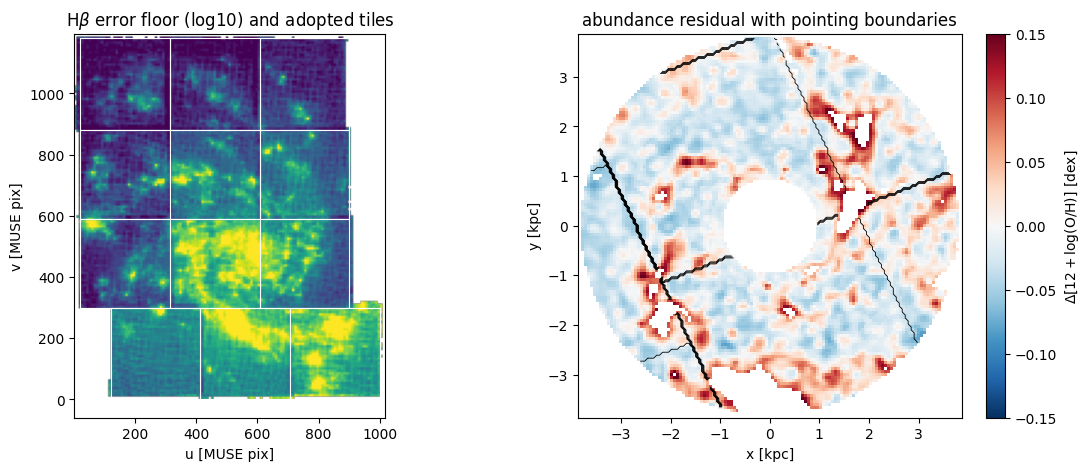

In [2]:
from astropy.io import fits
labels_info = pointing_labels(DATA_ROOT, GALAXY_NAME, pixel_map)
pointing = labels_info["pointing"]; valid = pixel_map["valid_mask"].astype(bool)
n_pointings = int(pointing.max()) + 1
tile_counts = np.bincount(pointing[valid], minlength=n_pointings)
np.savez_compressed(OUTPUT_DIR / f"{GALAXY_NAME.lower()}_pointing_labels_faceon.npz", **labels_info, valid=valid)
print(f"{n_pointings} pointings; valid cells per pointing: {tile_counts.tolist()}; geometry fit residual "
      f"{float(labels_info['geometry_fit_residual_kpc']):.3f} kpc")

error_plane = fits.getdata(DATA_ROOT / TILE_GALAXIES[GALAXY_NAME]["maps"], "HB4861_FLUX_ERR")
tile_map, u0, v0, cell = noise_floor_tiles(error_plane, float(labels_info["angle"]))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), constrained_layout=True)
axes[0].imshow(tile_map, origin="lower", cmap="viridis", vmin=np.nanpercentile(tile_map, 3), vmax=np.nanpercentile(tile_map, 97),
               extent=[u0, u0 + tile_map.shape[1] * cell, v0, v0 + tile_map.shape[0] * cell])
for (u1, u2, v1, v2) in labels_info["rects"]:
    axes[0].plot([u1, u2, u2, u1, u1], [v1, v1, v2, v2, v1], color="w", lw=0.8)
axes[0].set(title=r"H$\beta$ error floor (log10) and adopted tiles", xlabel="u [MUSE pix]", ylabel="v [MUSE pix]")
image = axes[1].pcolormesh(pixel_map["x_grid_kpc"], pixel_map["y_grid_kpc"], np.where(valid, pixel_map["residual_dex"], np.nan), cmap="RdBu_r", vmin=-0.15, vmax=0.15, shading="nearest")
axes[1].contour(pixel_map["x_grid_kpc"], pixel_map["y_grid_kpc"], np.where(valid, pointing, np.nan), levels=np.arange(n_pointings) + 0.5, colors="k", linewidths=0.6)
axes[1].set(aspect="equal", xlabel="x [kpc]", ylabel="y [kpc]", title="abundance residual with pointing boundaries")
fig.colorbar(image, ax=axes[1], label=r"$\Delta[12+\log({\rm O/H})]$ [dex]")
fig.savefig(OUTPUT_DIR / f"{GALAXY_NAME.lower()}_pointing_tiles.png", **FIG_KW); plt.show()

## Same-pointing / cross-pointing statistics and $D(r)$

Every pixel pair is assigned to the same- or cross-pointing subset.  $\xi_{\rm all}$ is the stage-1
statistic (checked below), and $D(r)=\xi_{\rm same}-\xi_{\rm cross}$ is compressed to 0.3-kpc bins with
pair-count weights.  The 48-block delete-one jackknife (4 equal-area radial $\times$ 12 azimuthal blocks,
re-detrending each time) gives the covariance of the stacked vector $[\xi_{\rm all}, D]$.  A randomly shifted
tiling (60 draws) gives the null distribution of the shoulder-averaged $D$.

pointing split: 8 pointings, 48 jackknife blocks; D = [ 0.058   0.0105 -0.0347 -0.0027  0.0283  0.0384  0.0217 -0.0167 -0.0454
 -0.0327]
max |xi_all - stage-1 xi_centered| = 1.3706360568743747e-07


shoulder-averaged D = +0.0057; shifted-tiling null +0.0060 +- 0.0329 -> z = -0.01, p = 0.467


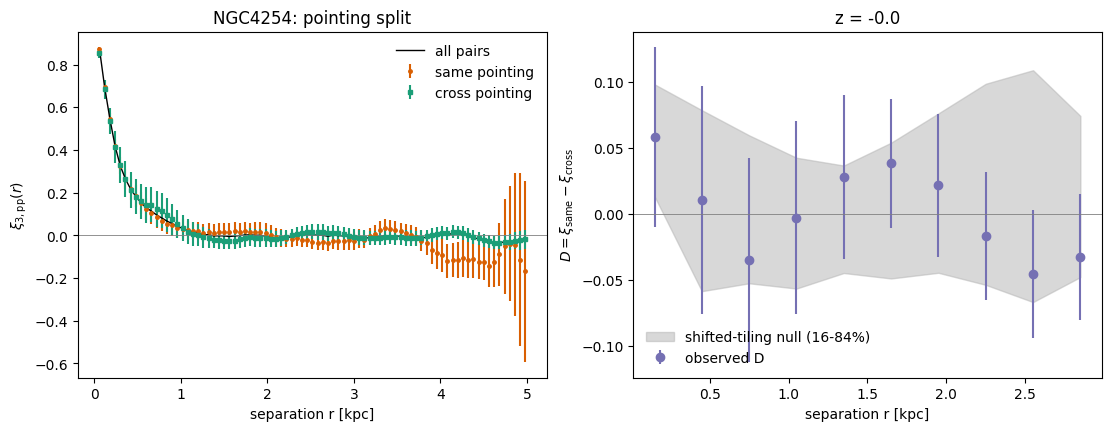

In [3]:
split = kew.split_statistics(pixel_map, pointing)
nb = len(split["xi_all"]); nc = len(split["D"])
print("max |xi_all - stage-1 xi_centered| =", float(np.nanmax(np.abs(split["xi_all"] - diagnostics["xi_centered"]))))
rng = np.random.default_rng(1)
radius_grid = np.hypot(pixel_map["x_grid_kpc"], pixel_map["y_grid_kpc"])
z_field = kew.detrend(pixel_map["residual_dex"], valid, radius_grid)
pair_statistic = kew.PairStatistic(valid)
shoulder = (split["r"] >= 0.6) & (split["r"] <= 2.5)
null_D = []
for _ in range(60):
    shifted = shifted_tiling_labels(labels_info, rng)
    _, xs_, xc_, cs_, cc_ = pair_statistic.split(z_field, valid, shifted)
    null_D.append(kew.compress_difference(split["r"], xs_, xc_, cs_, cc_)[0])
null_D = np.array(null_D)
coarse_shoulder = slice(2, 8)   # 0.6-2.4 kpc
D_shoulder = float(np.nanmean(split["D"][coarse_shoulder])); null_shoulder = np.nanmean(null_D[:, coarse_shoulder], axis=1)
pointing_z = (D_shoulder - null_shoulder.mean()) / null_shoulder.std(); pointing_p = float(np.mean(null_shoulder >= D_shoulder))
print(f"shoulder-averaged D = {D_shoulder:+.4f}; shifted-tiling null {null_shoulder.mean():+.4f} +- {null_shoulder.std():.4f} -> z = {pointing_z:+.2f}, p = {pointing_p:.3f}")
np.savez_compressed(OUTPUT_DIR / f"{GALAXY_NAME.lower()}_split_data.npz", **split, null_D=null_D, pointing_z=pointing_z, pointing_p=pointing_p)
Table({"r_kpc": split["r"], "xi_all": split["xi_all"], "xi_same": split["xi_same"], "xi_cross": split["xi_cross"],
       "pairs_same": split["pairs_same"] / 2, "pairs_cross": split["pairs_cross"] / 2, "err_same_jackknife": split["err_same_fine"], "err_cross_jackknife": split["err_cross_fine"]}
      ).write(OUTPUT_DIR / f"{GALAXY_NAME.lower()}_pointing_split.csv", format="ascii.csv", overwrite=True)
Table({"r_lo_kpc": split["coarse_edges"][:-1], "r_hi_kpc": split["coarse_edges"][1:], "D": split["D"], "D_jackknife_error": split["D_err"]}
      ).write(OUTPUT_DIR / f"{GALAXY_NAME.lower()}_pointing_difference.csv", format="ascii.csv", overwrite=True)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)
axes[0].errorbar(split["r"], split["xi_same"], split["err_same_fine"], fmt="o", ms=2.5, color="#d95f02", label="same pointing")
axes[0].errorbar(split["r"], split["xi_cross"], split["err_cross_fine"], fmt="s", ms=2.5, color="#1b9e77", label="cross pointing")
axes[0].plot(split["r"], split["xi_all"], color="k", lw=1, label="all pairs")
axes[0].axhline(0, color="0.5", lw=0.6); axes[0].set(xlabel="separation r [kpc]", ylabel=r"$\xi_{3,{\rm pp}}(r)$", title=f"{GALAXY_NAME}: pointing split"); axes[0].legend(frameon=False)
centres = 0.5 * (split["coarse_edges"][:-1] + split["coarse_edges"][1:])
axes[1].errorbar(centres, split["D"], split["D_err"], fmt="o", color="#7570b3", label="observed D")
axes[1].fill_between(centres, np.nanpercentile(null_D, 16, 0), np.nanpercentile(null_D, 84, 0), color="0.7", alpha=0.5, label="shifted-tiling null (16-84%)")
axes[1].axhline(0, color="0.5", lw=0.6); axes[1].set(xlabel="separation r [kpc]", ylabel=r"$D=\xi_{\rm same}-\xi_{\rm cross}$", title=f"z = {pointing_z:+.1f}"); axes[1].legend(frameon=False)
fig.savefig(OUTPUT_DIR / f"{GALAXY_NAME.lower()}_pointing_split.png", **FIG_KW); plt.show()

## Exact window responses

For every $h_R^{-1}$ node the projected numerator and denominator of each KTZ component are
accumulated over the pixel pairs of each subset (all pairs enumerated, no subsampling), on a kernel-radius
grid that is later contracted with the KT18 and $C_{\rm NP}$ kernels.  The projected pointing indicator
$\sum_p \mathbf w_p \mathbf w_p^{\sf T}$ is accumulated in the same pass.  Same + cross recombine to the
all-pair response exactly.  The responses are cached with the stage-1 signature.

In [4]:
response_signature = hashlib.sha256(json.dumps({"version": 1, "stage1": stage1_signature, "tiles": labels_info["rects"].tolist(), "angle": float(labels_info["angle"]),
                                                  "slope_grid": stage1_slope_grid.tolist(), "edges": kew.FINE_EDGES.tolist()}, sort_keys=True).encode()).hexdigest()
responses = {}
for selection in ("same", "cross"):
    path = OUTPUT_DIR / f"{GALAXY_NAME.lower()}_window_response_{selection}.npz"
    loaded = False
    if path.exists():
        with np.load(path, allow_pickle=False) as cached:
            if "signature" in cached.files and str(cached["signature"].item()) == response_signature:
                responses[selection] = {k: cached[k] for k in cached.files}; loaded = True
    if not loaded:
        log_path = OUTPUT_DIR / f"{GALAXY_NAME.lower()}_window_response_{selection}.log"
        with log_path.open("a") as handle:
            def log(msg, handle=handle):
                print(msg, flush=True); handle.write(msg + "\n"); handle.flush()
            responses[selection] = kew.build_window_response(pixel_map, pointing, morphology["r_ref_kpc"], selection=selection,
                                                             rate_log_slope_grid=stage1_slope_grid, log=log)
        np.savez_compressed(path, signature=np.asarray(response_signature), **responses[selection])
    else:
        print(f"Loaded cached {selection}-pair window response: {path.name}")
counts_same, counts_cross = responses["same"]["ordered_pair_counts"], responses["cross"]["ordered_pair_counts"]
assert np.allclose(counts_same, split["pairs_same"]) and np.allclose(counts_cross, split["pairs_cross"]), "pair counts differ between the response and the data split"
weight_same = counts_same / (counts_same + counts_cross); weight_cross = 1 - weight_same
response_all = dict(kernel_radius=responses["same"]["kernel_radius"], rate_log_slope_grid=responses["same"]["rate_log_slope_grid"],
                    response=np.nan_to_num(responses["same"]["response"]) * weight_same[None, None, None, :, None] + np.nan_to_num(responses["cross"]["response"]) * weight_cross[None, None, None, :, None],
                    mean_response=np.nan_to_num(responses["same"]["mean_response"]) * weight_same + np.nan_to_num(responses["cross"]["mean_response"]) * weight_cross,
                    delta_response=np.nan_to_num(responses["same"]["delta_response"]) * weight_same + np.nan_to_num(responses["cross"]["delta_response"]) * weight_cross,
                    ordered_pair_counts=counts_same + counts_cross)
np.savez_compressed(OUTPUT_DIR / f"{GALAXY_NAME.lower()}_window_response_all.npz", signature=np.asarray(response_signature), **response_all)
print("pointing-term response (unit sigma_q^2), first coarse bins of the same/cross difference:",
      np.round((responses["same"]["delta_response"][0] / np.maximum(responses["same"]["delta_response"][1], 1e-12))[:5], 3))

[same] pair geometry 8s; ordered pairs per bin min/max 1312/720734


[same] rate_log_slope node 1/5: -0.3500  (8s)


[same] rate_log_slope node 2/5: -0.1750  (37s)


[same] rate_log_slope node 3/5: +0.0000  (66s)


[same] rate_log_slope node 4/5: +0.1750  (95s)


[same] rate_log_slope node 5/5: +0.3500  (126s)


... (3 outputs left out)

[cross] rate_log_slope node 3/5: +0.0000  (73s)


[cross] rate_log_slope node 4/5: +0.1750  (104s)


[cross] rate_log_slope node 5/5: +0.3500  (137s)


pointing-term response (unit sigma_q^2), first coarse bins of the same/cross difference: [0.999 0.999 0.998 0.997 0.996]


## Joint covariance and likelihood

The $\xi_{\rm all}$ block is the stage-1 regularised covariance (jackknife + line-flux Monte Carlo + selection
systematic, 0.35 shrinkage, 0.01 floor).  The Monte Carlo and selection pieces are common to both pair subsets
and cancel in $D$ to first order, so the $D$ block and the cross block use the jackknife alone with the same
shrinkage and floor.

In [5]:
covariance_joint = kew.joint_covariance(fit_covariance, split["cov_jk"], nb)
eigenvalues = np.linalg.eigvalsh(covariance_joint)
print(f"joint covariance: {nb} + {nc} data; eigenvalues {eigenvalues.min():.2e} .. {eigenvalues.max():.2e}")
np.savez_compressed(OUTPUT_DIR / f"{GALAXY_NAME.lower()}_joint_covariance.npz", covariance=covariance_joint)

def make_model(use_D=True, sigma_q_max=3.0):
    return kew.SplitKTZ(morphology, diagnostics, fit_covariance, response_all, responses["same"], responses["cross"], split, covariance_joint,
                        emulator_grids, use_D=use_D, sigma_q_max=sigma_q_max, src_length_bounds=(ELL_SRC_LOWER_KPC, None), eta_prior=ETA_PRIOR)

model_A = make_model()                       # sigma_q free
model_R0 = make_model(sigma_q_max=0.0)       # sigma_q == 0
print(f"eta prior: {ETA_PRIOR} on (0, {model_A.eta_positive_limit:.3f}); h_R^-1 prior N({-model_A.slope_mu:+.3f}, {model_A.slope_sd:.3f}) kpc^-1; "
      f"ell_src in [{model_A.src_lo:.3f}, {model_A.src_hi:.2f}] kpc; sigma_q uniform on [0, 3]")

joint covariance: 83 + 10 data; eigenvalues 1.26e-04 .. 2.02e-02


eta prior: flat on (0, 1.201); h_R^-1 prior N(+0.378, 0.056) kpc^-1; ell_src in [0.120, 2.50] kpc; sigma_q uniform on [0, 3]


## Sampling

Runs start from the stage-1 posterior (thinned transport chain) with $\sigma_q$ drawn uniformly on [0.05, 0.9].
Chains are cached with the response signature and the sampler settings.

In [6]:
with np.load(STAGE1_DIR / f"{GALAXY_NAME.lower()}_transport_chain.npz", allow_pickle=False) as cached:
    stage1_samples = cached["internal_chain"][int(cached["burn_steps"].item())::20].reshape(-1, 7)

def run_cached(tag, model, n_steps, kt18=False, seed=0):
    path = OUTPUT_DIR / f"{GALAXY_NAME.lower()}_chain_{tag}.npz"
    signature = hashlib.sha256(json.dumps({"response": response_signature, "steps": n_steps, "kt18": kt18, "seed": seed, "eta_prior": ETA_PRIOR,
                                            "ell_src_lower": ELL_SRC_LOWER_KPC, "sigma_q_max": model.sigma_q_max, "use_D": model.use_D}, sort_keys=True).encode()).hexdigest()
    if path.exists():
        with np.load(path, allow_pickle=False) as cached:
            if str(cached["signature"].item()) == signature:
                print(f"[{tag}] loaded cached chain ({cached['samples'].shape[0]:,} samples, max R-hat {np.nanmax(cached['rhat']):.3f})")
                return {k: cached[k] for k in cached.files}
    rng = np.random.default_rng(seed)
    if kt18:
        candidate = stage1_samples[rng.choice(len(stage1_samples), 4000, replace=False), :2]
        candidate = candidate + rng.normal(0, 0.02, candidate.shape)
    else:
        candidate = stage1_samples[rng.choice(len(stage1_samples), 4000, replace=False)]
        candidate = np.c_[candidate, np.zeros(len(candidate)) if model.sigma_q_max == 0 else rng.uniform(0.05, 0.9, len(candidate))]
    finite = np.isfinite(model.log_probability(candidate, kt18)); candidate = candidate[finite]
    n_walkers = 32 if kt18 else 64
    start = candidate[rng.choice(len(candidate), n_walkers, replace=False)]
    t0 = time.time()
    result = kew.run_ensemble(model, start, n_steps, kt18=kt18, seed=int(rng.integers(2**31)), thin=5, burn=n_steps // 4,
                              progress=lambda k: print(f"[{tag}] step {k:,}/{n_steps:,} ({time.time() - t0:.0f} s)", flush=True) if k % 10000 == 0 else None)
    out = dict(samples=result["samples"], sample_lp=result["sample_lp"], rhat=result["rhat"], acceptance=result["acceptance"], burn=np.asarray(result["burn"]),
               signature=np.asarray(signature))
    np.savez_compressed(path, **out)
    print(f"[{tag}] done in {time.time() - t0:.0f} s; split R-hat max {np.nanmax(result['rhat']):.3f}; mean acceptance {result['acceptance'].mean():.3f}")
    return out

chains = {"A": run_cached("A", model_A, N_MCMC_STEPS, seed=628), "R0": run_cached("R0", model_R0, N_MCMC_STEPS, seed=1566),
          "KT18": run_cached("KT18", model_A, N_KT18_STEPS, kt18=True, seed=4254)}

[A] step 10,000/100,000 (39 s)


[A] step 20,000/100,000 (79 s)


[A] step 30,000/100,000 (122 s)


[A] step 40,000/100,000 (162 s)


[A] step 50,000/100,000 (200 s)


[A] step 60,000/100,000 (240 s)


... (15 outputs left out)

/home/claude/ktzobs/scripts/ktz_exact_window.py:480: RuntimeWarning: invalid value encountered in divide
  return np.sqrt(((half-1)*within/half+between/half)/within)


[R0] done in 397 s; split R-hat max 1.009; mean acceptance 0.265


[KT18] step 10,000/10,000 (6 s)


[KT18] done in 6 s; split R-hat max 1.005; mean acceptance 0.711


## Posterior summaries

In [7]:
summaries = {}; curves = {}
for tag, model in (("A", model_A), ("R0", model_R0)):
    summaries[tag], curves[tag] = kew.summarise_joint(model, chains[tag]["samples"])
    summaries[tag]["rhat_max"] = float(np.nanmax(chains[tag]["rhat"])); summaries[tag]["acceptance"] = float(chains[tag]["acceptance"].mean())
    np.savez_compressed(OUTPUT_DIR / f"{GALAXY_NAME.lower()}_curves_{tag}.npz", **curves[tag])
kt18_samples = chains["KT18"]["samples"]
kt18_curves = model_A.predict_kt18(kt18_samples[np.random.default_rng(3).choice(len(kt18_samples), 2000, replace=False)])
kt18_median = np.nanmedian(kt18_curves, 0)
kt18_ell = np.percentile(np.exp(kt18_samples[:, 0]), [16, 50, 84]); kt18_eps = np.percentile(1 / (1 + np.exp(-kt18_samples[:, 1])), [16, 50, 84])
summaries["KT18"] = dict(chi2_all_median_curve=model_A.chi2(kt18_median), params={"ell_star": kt18_ell.tolist(), "epsilon": kt18_eps.tolist()},
                         rhat_max=float(np.nanmax(chains["KT18"]["rhat"])), shoulder_model=float(np.nanmean(kt18_median[(model_A.data['r_kpc'] >= .6) & (model_A.data['r_kpc'] <= 2.5)])))
np.savez_compressed(OUTPUT_DIR / f"{GALAXY_NAME.lower()}_curves_KT18.npz", r=model_A.data["r_kpc"], xi_median=kt18_median,
                    xi_p16=np.nanpercentile(kt18_curves, 16, 0), xi_p84=np.nanpercentile(kt18_curves, 84, 0))
summaries["settings"] = dict(n_mcmc_steps=N_MCMC_STEPS, eta_prior=ETA_PRIOR, ell_src_lower_kpc=ELL_SRC_LOWER_KPC, n_pointings=n_pointings,
                             pointing_z=float(pointing_z), pointing_p=pointing_p, response_signature=response_signature, stage1_signature=stage1_signature)
json.dump(summaries, (OUTPUT_DIR / f"{GALAXY_NAME.lower()}_exact_window_summary.json").open("w"), indent=1)

rows = []
for name, label in (("ell_star", "ell_star [kpc]"), ("epsilon", "epsilon"), ("beta_src", "beta_src"), ("eta", "eta"), ("inv_h_R", "h_R^-1 [kpc^-1]"),
                    ("A_src", "A_src"), ("ell_src", "ell_src [kpc]"), ("kappa", "kappa [kpc^2 Gyr^-1]"), ("t_star", "t_star [Gyr]"), ("sigma_q", "sigma_q")):
    rows.append([label] + [f"{summaries[t]['params'][name][1]:.3f} [{summaries[t]['params'][name][0]:.3f}, {summaries[t]['params'][name][2]:.3f}]" for t in ("A", "R0")])
table = Table(rows=rows, names=("parameter", "A (sigma_q free)", "R0 (sigma_q = 0)"))
table.write(OUTPUT_DIR / f"{GALAXY_NAME.lower()}_exact_window_posterior.csv", format="ascii.csv", overwrite=True)
display(table)
for tag in ("A", "R0"):
    s = summaries[tag]
    print(f"[{tag}] chi2(xi_all, median curve) = {s['chi2_all_median_curve']:.2f}; joint chi2 = {s['chi2_joint_median']:.2f} for {s['n_data']} data; "
          f"shoulder obs {s['shoulder_obs']:.4f} = KTZ {s['shoulder_ktz']:.4f} + pointing {s['shoulder_pointing']:.4f}; "
          f"pointing variance fraction {100 * s['pointing_variance_fraction'][1]:.1f}% [{100 * s['pointing_variance_fraction'][0]:.1f}, {100 * s['pointing_variance_fraction'][2]:.1f}]; R-hat max {s['rhat_max']:.3f}")
print(f"[KT18] chi2(xi_all, median curve) = {summaries['KT18']['chi2_all_median_curve']:.2f}; ell_star = {kt18_ell[1]:.3f} [{kt18_ell[0]:.3f}, {kt18_ell[2]:.3f}] kpc")

parameter,A (sigma_q free),R0 (sigma_q = 0)
str20,str21,str21
ell_star [kpc],"0.195 [0.146, 0.263]","0.197 [0.144, 0.274]"
epsilon,"0.156 [0.094, 0.256]","0.153 [0.090, 0.264]"
beta_src,"7.711 [3.607, 16.713]","8.138 [3.511, 18.683]"
eta,"0.462 [0.184, 0.794]","0.437 [0.142, 0.796]"
h_R^-1 [kpc^-1],"0.322 [0.288, 0.342]","0.321 [0.282, 0.342]"
A_src,"0.043 [0.015, 0.154]","0.038 [0.014, 0.152]"
ell_src [kpc],"0.350 [0.171, 0.592]","0.369 [0.168, 0.638]"
kappa [kpc^2 Gyr^-1],"0.196 [0.085, 0.453]","0.194 [0.080, 0.489]"
t_star [Gyr],"0.083 [0.058, 0.151]","0.084 [0.057, 0.161]"


[A] chi2(xi_all, median curve) = 5.64; joint chi2 = 7.79 for 93 data; shoulder obs 0.0193 = KTZ 0.0143 + pointing 0.0024; pointing variance fraction 0.6% [0.1, 1.9]; R-hat max 1.008
[R0] chi2(xi_all, median curve) = 5.68; joint chi2 = 7.52 for 93 data; shoulder obs 0.0193 = KTZ 0.0146 + pointing 0.0000; pointing variance fraction 0.0% [0.0, 0.0]; R-hat max 1.009
[KT18] chi2(xi_all, median curve) = 7.53; ell_star = 0.415 [0.355, 0.489] kpc


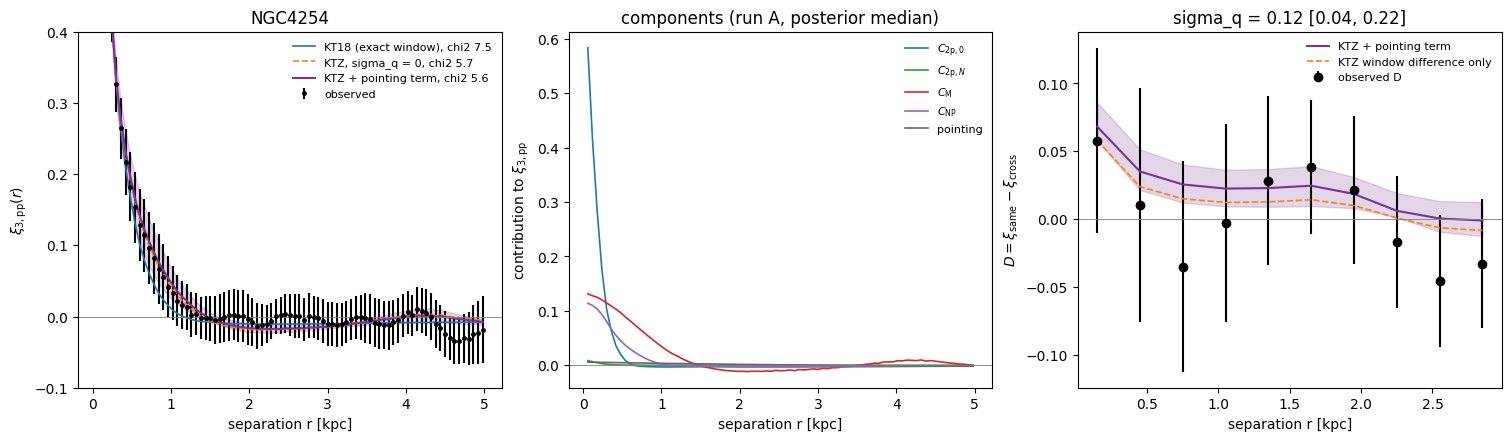

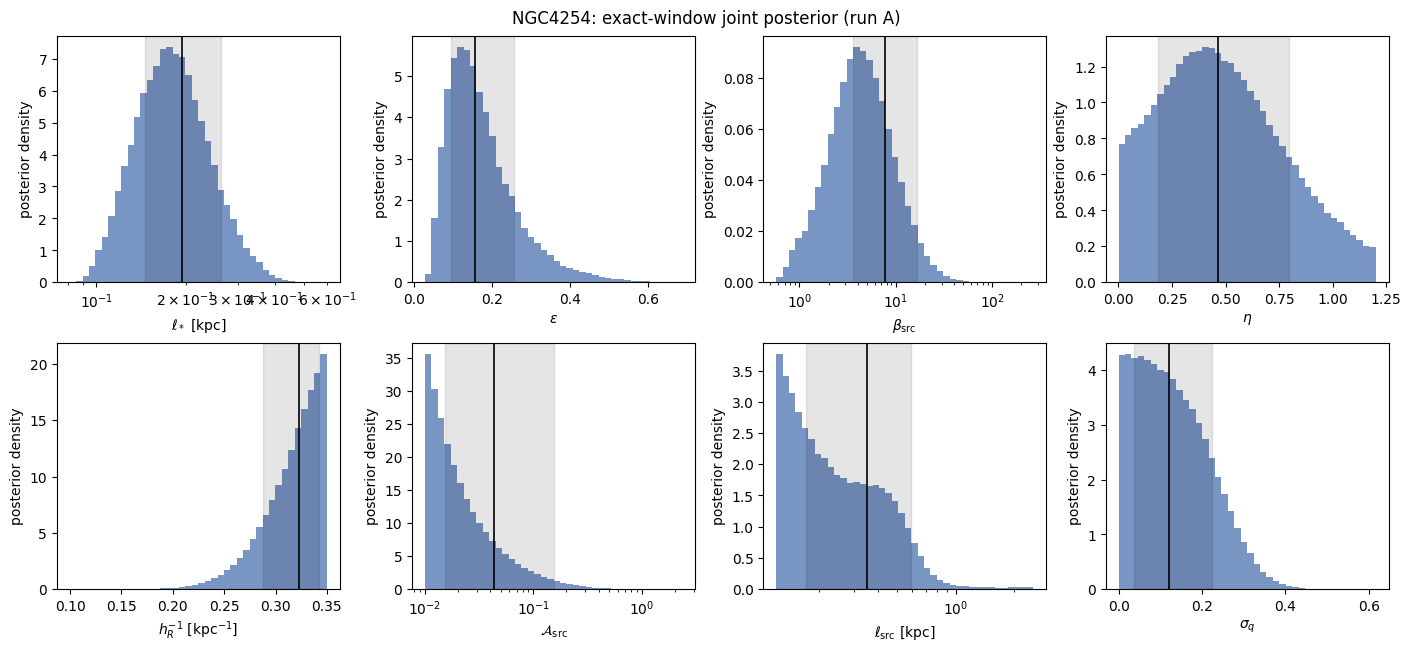

In [8]:
r = model_A.data["r_kpc"]; xi_obs = model_A.data["xi_centered"]; xi_err = np.sqrt(np.diag(fit_covariance))
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), constrained_layout=True)
axes[0].errorbar(r, xi_obs, xi_err, fmt="o", ms=2.5, color="k", label="observed")
axes[0].plot(r, kt18_median, color="#1f77b4", lw=1.2, label=f"KT18 (exact window), chi2 {summaries['KT18']['chi2_all_median_curve']:.1f}")
axes[0].plot(r, curves["R0"]["xi_median"], color="#ff7f0e", lw=1.2, ls="--", label=f"KTZ, sigma_q = 0, chi2 {summaries['R0']['chi2_all_median_curve']:.1f}")
axes[0].fill_between(r, curves["A"]["xi_p16"], curves["A"]["xi_p84"], color="#7b3294", alpha=0.2)
axes[0].plot(r, curves["A"]["xi_median"], color="#7b3294", lw=1.5, label=f"KTZ + pointing term, chi2 {summaries['A']['chi2_all_median_curve']:.1f}")
axes[0].axhline(0, color="0.5", lw=0.6); axes[0].set(xlabel="separation r [kpc]", ylabel=r"$\xi_{3,{\rm pp}}(r)$", title=GALAXY_NAME, ylim=(-0.1, 0.4)); axes[0].legend(frameon=False, fontsize=8)
comp = curves["A"]["comp_median"]
for k, (name, color) in enumerate((("$C_{\\rm 2p,0}$", "#1f77b4"), ("$C_{{\\rm 2p},N}$", "#2ca02c"), ("$C_{\\rm M}$", "#d62728"), ("$C_{\\rm NP}$", "#9467bd"), ("pointing", "0.4"))):
    axes[1].plot(r, comp[k], color=color, lw=1.2, label=name)
axes[1].axhline(0, color="0.5", lw=0.6); axes[1].set(xlabel="separation r [kpc]", ylabel="contribution to $\\xi_{3,{\\rm pp}}$", title="components (run A, posterior median)"); axes[1].legend(frameon=False, fontsize=8)
centres = 0.5 * (split["coarse_edges"][:-1] + split["coarse_edges"][1:])
axes[2].errorbar(centres, split["D"], split["D_err"], fmt="o", color="k", label="observed D")
axes[2].fill_between(centres, curves["A"]["D_p16"], curves["A"]["D_p84"], color="#7b3294", alpha=0.2)
axes[2].plot(centres, curves["A"]["D_median"], color="#7b3294", lw=1.5, label="KTZ + pointing term")
axes[2].plot(centres, curves["R0"]["D_median"], color="#ff7f0e", lw=1.2, ls="--", label="KTZ window difference only")
axes[2].axhline(0, color="0.5", lw=0.6); axes[2].set(xlabel="separation r [kpc]", ylabel=r"$D=\xi_{\rm same}-\xi_{\rm cross}$", title=f"sigma_q = {summaries['A']['params']['sigma_q'][1]:.2f} [{summaries['A']['params']['sigma_q'][0]:.2f}, {summaries['A']['params']['sigma_q'][2]:.2f}]"); axes[2].legend(frameon=False, fontsize=8)
fig.savefig(OUTPUT_DIR / f"{GALAXY_NAME.lower()}_exact_window_fit.png", **FIG_KW); plt.show()

samples = chains["A"]["samples"]; derived = np.asarray(model_A.derived(samples[:, :7])).T
fig, axes = plt.subplots(2, 4, figsize=(14, 6.4), constrained_layout=True)
specs = ((derived[:, 0], r"$\ell_*$ [kpc]", True), (derived[:, 1], r"$\epsilon$", False), (derived[:, 2], r"$\beta_{\rm src}$", True), (derived[:, 3], r"$\eta$", False),
         (-samples[:, 4], r"$h_R^{-1}$ [kpc$^{-1}$]", False), (derived[:, 7], r"${\cal A}_{\rm src}$", True), (derived[:, 8], r"$\ell_{\rm src}$ [kpc]", True), (samples[:, 7], r"$\sigma_q$", False))
for axis, (values, label, log_scale) in zip(axes.ravel(), specs):
    bins = np.geomspace(values[values > 0].min(), values.max(), 41) if log_scale else 40
    axis.hist(values, bins=bins, density=True, color="#4c72b0", alpha=0.75)
    lo, med, hi = np.percentile(values, [16, 50, 84]); axis.axvline(med, color="k", lw=1.2); axis.axvspan(lo, hi, color="k", alpha=0.1)
    axis.set(xlabel=label, ylabel="posterior density")
    if log_scale: axis.set_xscale("log")
fig.suptitle(f"{GALAXY_NAME}: exact-window joint posterior (run A)")
fig.savefig(OUTPUT_DIR / f"{GALAXY_NAME.lower()}_exact_window_posterior.png", **FIG_KW); plt.show()

## Nested-model evidence (optional)

Bayesian evidence with `dynesty` for L0 (KT18), L1 (+ arm-modulated source: $C_{{\rm 2p},N}$ + $C_{\rm M}$), L1n (+ $C_{\rm NP}$),
L2 (complete KTZ), each with and without the pointing term (suffix q), on the joint data vector with the priors above.
Several hours per galaxy; results are written to `*_exact_window_evidence.json`.

In [9]:
if RUN_EVIDENCE:
    from scripts.ktz_exact_window_evidence import evidence_table
    evidence = evidence_table(model_A, models=("L0", "L0q", "L1", "L1q", "L1n", "L1nq", "L2", "L2q"), nlive=400, log=print)
    json.dump(evidence, (OUTPUT_DIR / f"{GALAXY_NAME.lower()}_exact_window_evidence.json").open("w"), indent=1)
    display(Table(rows=[[k, v["n_params"], round(v["logZ"], 2), round(v["chi2_min"], 2), round(v["ell_star"][1], 3)] for k, v in evidence.items()],
                  names=("model", "k", "log Z", "chi2_min", "ell_star")))
else:
    print("RUN_EVIDENCE = False: evidence table not recomputed in this execution.")

RUN_EVIDENCE = False: evidence table not recomputed in this execution.
